<a href="https://colab.research.google.com/github/ikah-uni/MMA3001-Concrete-Strength-Prediction/blob/main/MMA3001_Concrete_Strength.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [11]:

import os

print(os.listdir("/content"))


['.config', 'Concrete_Data.xls', 'sample_data']


Use Pandas to read the excel sheet

In [39]:

import pandas as pd

dataset_url = "https://raw.githubusercontent.com/ikah-uni/MMA3001-Concrete-Strength-Prediction/main/Concrete_Data.xls"

# Install support for older Excel (.xls) files
%pip -q install xlrd

# Read the Excel file and store it in a DataFrame
df = pd.read_excel(dataset_url)

# Display the first five rows
display(df.head())

# Display the number of rows and columns
print("Dataset shape:", df.shape)


,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


Dataset shape: (1030, 9)


Change the column headings to improve readability

In [13]:

# Rename columns for easier use
df.columns = [
    "Cement",
    "Blast_Furnace_Slag",
    "Fly_Ash",
    "Water",
    "Superplasticizer",
    "Coarse_Aggregate",
    "Fine_Aggregate",
    "Age",
    "Strength"
]

# Display the first five rows
display(df.head())


,Cement,Blast_Furnace_Slag,Fly_Ash,Water,Superplasticizer,Coarse_Aggregate,Fine_Aggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


**Data Audit**

In [14]:

# Check dataset dimensions
print("Dataset shape:", df.shape)

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# Generate descriptive statistics
print("\nStatistical Summary:")
display(df.describe())

# Check duplicate observations
print("\nDuplicate rows:", df.duplicated().sum())


Dataset shape: (1030, 9)

Missing values:
Cement                0
Blast_Furnace_Slag    0
Fly_Ash               0
Water                 0
Superplasticizer      0
Coarse_Aggregate      0
Fine_Aggregate        0
Age                   0
Strength              0
dtype: int64

Statistical Summary:


,Cement,Blast_Furnace_Slag,Fly_Ash,Water,Superplasticizer,Coarse_Aggregate,Fine_Aggregate,Age,Strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.165631,73.895485,54.187136,181.566359,6.203112,972.918592,773.578883,45.662136,35.817836
std,104.507142,86.279104,63.996469,21.355567,5.973492,77.753818,80.175427,63.169912,16.705679
min,102.000000,0.000000,0.000000,121.750000,0.000000,801.000000,594.000000,1.000000,2.331808
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.707115
50%,272.900000,22.000000,0.000000,185.000000,6.350000,968.000000,779.510000,28.000000,34.442774
75%,350.000000,142.950000,118.270000,192.000000,10.160000,1029.400000,824.000000,56.000000,46.136287
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.599225



Duplicate rows: 25


Check for impossible values

In [15]:

# Check for physically impossible values

material_columns = [
    "Cement", "Blast_Furnace_Slag", "Fly_Ash",
    "Water", "Superplasticizer",
    "Coarse_Aggregate", "Fine_Aggregate"
]

# Negative material quantities are invalid
negative_materials = (df[material_columns] < 0).any(axis=1)

# Age and strength must be positive
invalid_age = df["Age"] <= 0
invalid_strength = df["Strength"] <= 0

# Check for non-finite values
non_finite = ~np.isfinite(df.to_numpy()).all(axis=1)

invalid_rows = (
    negative_materials |
    invalid_age |
    invalid_strength |
    non_finite
)

print("Rows with invalid values:", invalid_rows.sum())
display(df[invalid_rows])


Rows with invalid values: 0


,Cement,Blast_Furnace_Slag,Fly_Ash,Water,Superplasticizer,Coarse_Aggregate,Fine_Aggregate,Age,Strength


Check for outliers within compressive strength output

In [16]:

# Calculate quartiles
Q1 = df["Strength"].quantile(0.25)
Q3 = df["Strength"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify potential outliers
outliers = df[
    (df["Strength"] < lower_bound) |
    (df["Strength"] > upper_bound)
]

print("Lower bound:", round(lower_bound, 2))
print("Upper bound:", round(upper_bound, 2))
print("Potential outliers:", len(outliers))

display(outliers)


Lower bound: -9.94
Upper bound: 79.78
Potential outliers: 4


,Cement,Blast_Furnace_Slag,Fly_Ash,Water,Superplasticizer,Coarse_Aggregate,Fine_Aggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
153,323.7,282.8,0.0,183.8,10.3,942.7,659.9,56,80.199848
181,389.9,189.0,0.0,145.9,22.0,944.7,755.8,91,82.599225
381,315.0,137.0,0.0,145.0,5.9,1130.0,745.0,28,81.751169


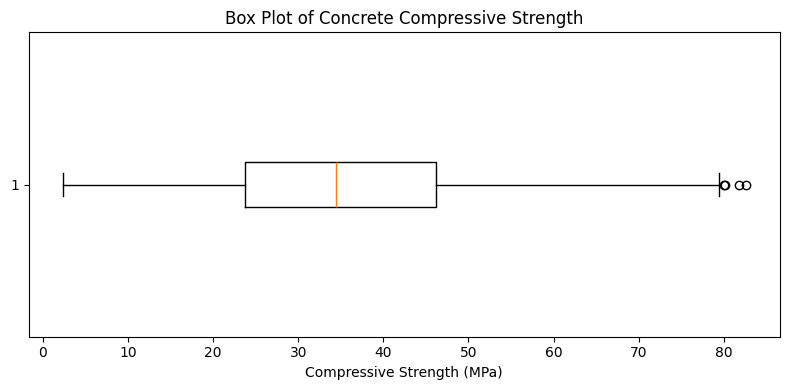

In [17]:

plt.figure(figsize=(8, 4))

plt.boxplot(df["Strength"], vert=False)

plt.xlabel("Compressive Strength (MPa)")
plt.title("Box Plot of Concrete Compressive Strength")

plt.tight_layout()
plt.show()


Removing duplicate rows

In [18]:

# Record original dataset size
original_rows = len(df)

# Remove exact duplicate observations
df = df.drop_duplicates().reset_index(drop=True)

# Calculate number of removed rows
removed_rows = original_rows - len(df)

print("Original observations:", original_rows)
print("Duplicates removed:", removed_rows)
print("Remaining observations:", len(df))


Original observations: 1030
Duplicates removed: 25
Remaining observations: 1005


**Exploratory Data Anaylsis**

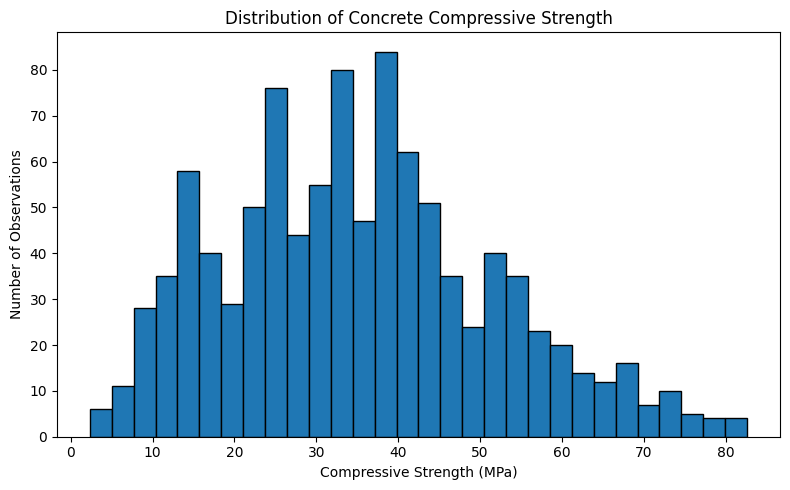

In [19]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(df["Strength"], bins=30, edgecolor="black")

plt.xlabel("Compressive Strength (MPa)")
plt.ylabel("Number of Observations")
plt.title("Distribution of Concrete Compressive Strength")

plt.tight_layout()
plt.show()


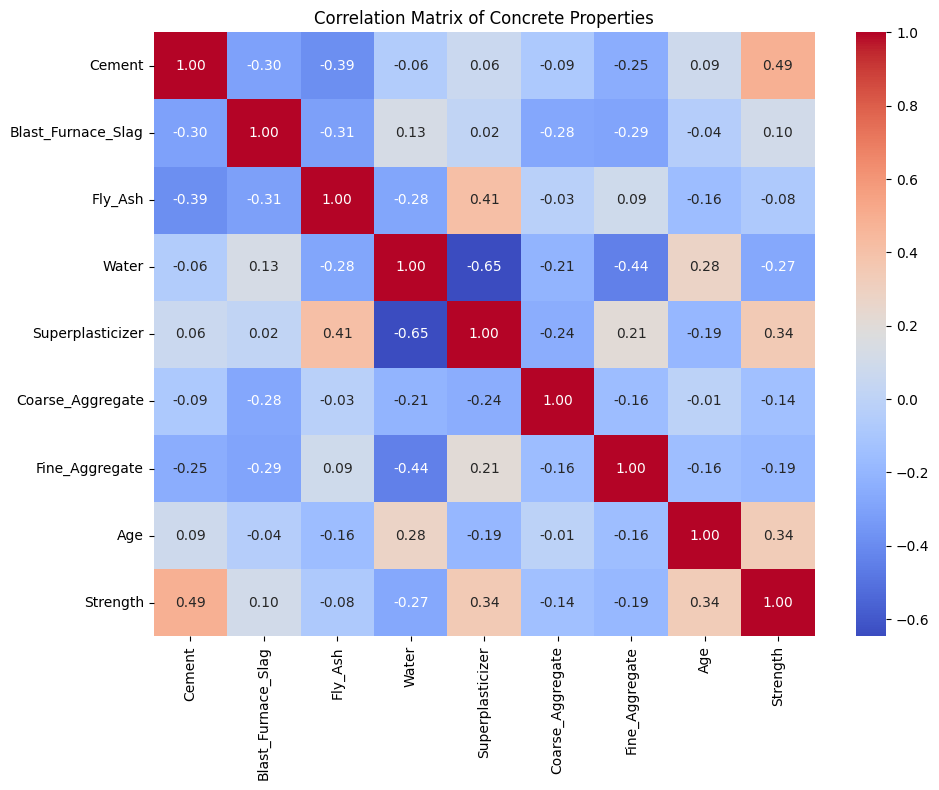

In [20]:

import seaborn as sns

plt.figure(figsize=(10, 8))

correlation = df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Concrete Properties")

plt.tight_layout()
plt.show()


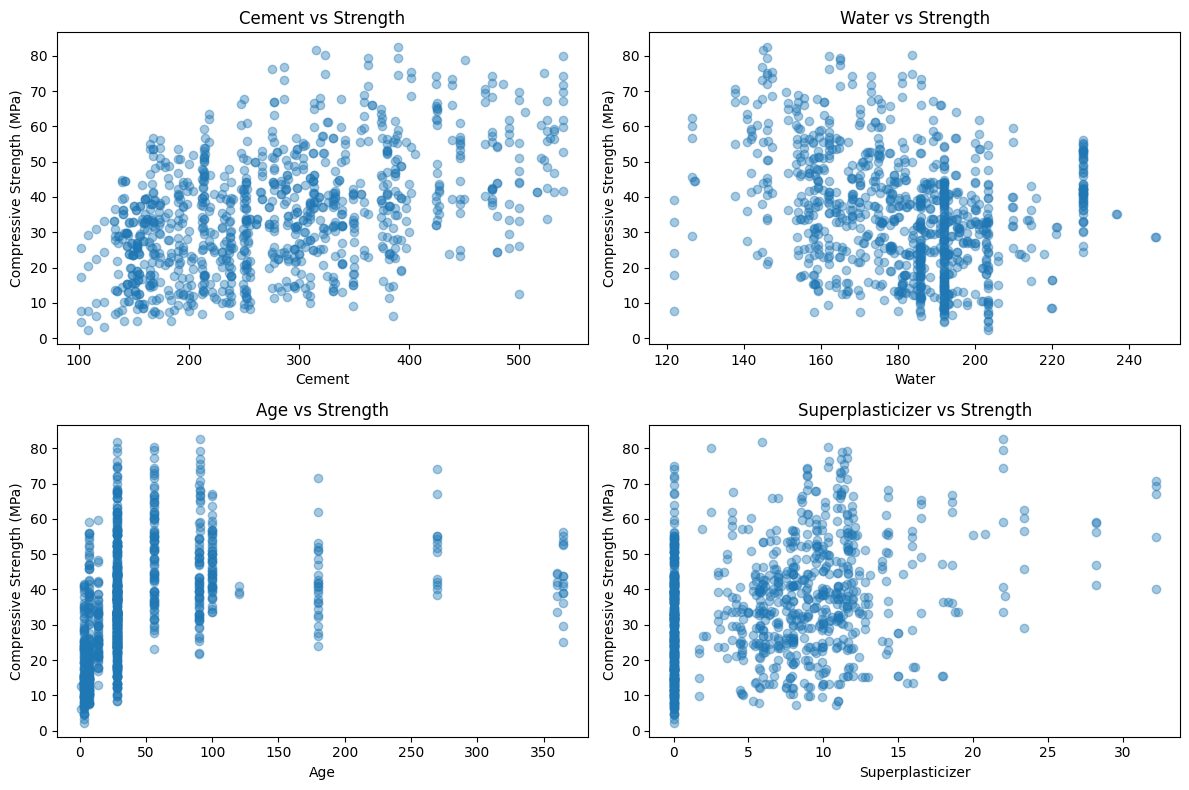

In [21]:

features = [
    "Cement",
    "Water",
    "Age",
    "Superplasticizer"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, feature in zip(axes.flat, features):
    ax.scatter(df[feature], df["Strength"], alpha=0.4)

    ax.set_xlabel(feature)
    ax.set_ylabel("Compressive Strength (MPa)")
    ax.set_title(f"{feature} vs Strength")

plt.tight_layout()
plt.show()


**Model Development**

In [22]:

# Separate the input features and target variable

X = df.drop(columns=["Strength"])
y = df["Strength"]

print("Input features:", X.shape)
print("Target values:", y.shape)
print("\nFeature names:")
print(X.columns.tolist())


Input features: (1005, 8)
Target values: (1005,)

Feature names:
['Cement', 'Blast_Furnace_Slag', 'Fly_Ash', 'Water', 'Superplasticizer', 'Coarse_Aggregate', 'Fine_Aggregate', 'Age']


Split dataset (&0% training, 15% validation, 15% testing)

In [23]:

from sklearn.model_selection import train_test_split

# First split: 70% training, 30% remaining
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42
)

# Second split: divide the remaining 30% equally
# into validation (15%) and testing (15%)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))


Training samples: 703
Validation samples: 151
Testing samples: 151


Train a baseline model

In [24]:

from sklearn.dummy import DummyRegressor

# Create a baseline model that always predicts the training mean
baseline_model = DummyRegressor(strategy="mean")

# Train the model using training data only
baseline_model.fit(X_train, y_train)

# Predict concrete strength for the validation dataset
y_val_baseline = baseline_model.predict(X_val)

print("Baseline prediction:", round(y_val_baseline[0], 2), "MPa")


Baseline prediction: 35.04 MPa


Baseline evaluation


In [25]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Evaluate baseline predictions on validation data
baseline_mae = mean_absolute_error(y_val, y_val_baseline)
baseline_rmse = np.sqrt(mean_squared_error(y_val, y_val_baseline))
baseline_r2 = r2_score(y_val, y_val_baseline)

print("Baseline Model Performance")
print("--------------------------")
print(f"MAE:  {baseline_mae:.3f} MPa")
print(f"RMSE: {baseline_rmse:.3f} MPa")
print(f"R²:   {baseline_r2:.3f}")


Baseline Model Performance
--------------------------
MAE:  14.595 MPa
RMSE: 18.008 MPa
R²:   -0.002


Linear Regression Model and Performance

In [26]:

from sklearn.linear_model import LinearRegression

# Create the Linear Regression model
linear_model = LinearRegression()

# Train the model using the training dataset
linear_model.fit(X_train, y_train)

# Predict compressive strength for the validation dataset
y_val_linear = linear_model.predict(X_val)

# Evaluate model performance
linear_mae = mean_absolute_error(y_val, y_val_linear)
linear_rmse = np.sqrt(mean_squared_error(y_val, y_val_linear))
linear_r2 = r2_score(y_val, y_val_linear)

print("Linear Regression Performance")
print("-----------------------------")
print(f"MAE:  {linear_mae:.3f} MPa")
print(f"RMSE: {linear_rmse:.3f} MPa")
print(f"R²:   {linear_r2:.3f}")


Linear Regression Performance
-----------------------------
MAE:  9.016 MPa
RMSE: 11.352 MPa
R²:   0.602


Decision Tree Regression Model and Performance

In [27]:

from sklearn.tree import DecisionTreeRegressor

# Create a Decision Tree model
tree_model = DecisionTreeRegressor(
    max_depth=5,
    random_state=42
)

# Train using training data only
tree_model.fit(X_train, y_train)

# Predict strengths for the validation dataset
y_val_tree = tree_model.predict(X_val)

# Evaluate performance
tree_mae = mean_absolute_error(y_val, y_val_tree)
tree_rmse = np.sqrt(mean_squared_error(y_val, y_val_tree))
tree_r2 = r2_score(y_val, y_val_tree)

print("Decision Tree Regression Performance")
print("------------------------------------")
print(f"MAE:  {tree_mae:.3f} MPa")
print(f"RMSE: {tree_rmse:.3f} MPa")
print(f"R²:   {tree_r2:.3f}")


Decision Tree Regression Performance
------------------------------------
MAE:  6.932 MPa
RMSE: 9.264 MPa
R²:   0.735


Investigating different max_depths and their perfomance

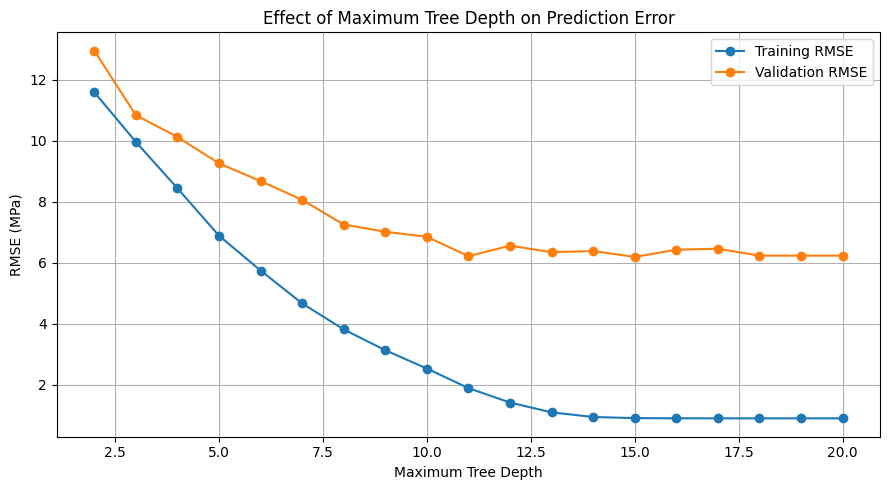

Best max_depth: 15
Lowest validation RMSE: 6.197 MPa


In [28]:

# Investigate the effect of Decision Tree depth

depths = range(2, 21)

train_rmse = []
val_rmse = []

for depth in depths:
    model = DecisionTreeRegressor(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_predictions = model.predict(X_train)
    val_predictions = model.predict(X_val)

    train_rmse.append(
        np.sqrt(mean_squared_error(y_train, train_predictions))
    )

    val_rmse.append(
        np.sqrt(mean_squared_error(y_val, val_predictions))
    )

# Plot the results
plt.figure(figsize=(9, 5))

plt.plot(depths, train_rmse, marker="o", label="Training RMSE")
plt.plot(depths, val_rmse, marker="o", label="Validation RMSE")

plt.xlabel("Maximum Tree Depth")
plt.ylabel("RMSE (MPa)")
plt.title("Effect of Maximum Tree Depth on Prediction Error")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Find the depth with the lowest validation RMSE
best_index = np.argmin(val_rmse)
best_depth = list(depths)[best_index]

print("Best max_depth:", best_depth)
print("Lowest validation RMSE:", round(val_rmse[best_index], 3), "MPa")


In [29]:

# Train the optimised Decision Tree
tree_model = DecisionTreeRegressor(
    max_depth=best_depth,
    random_state=42
)

tree_model.fit(X_train, y_train)

# Predict validation strengths
y_val_tree = tree_model.predict(X_val)

# Evaluate the optimised model
tree_mae = mean_absolute_error(y_val, y_val_tree)
tree_rmse = np.sqrt(mean_squared_error(y_val, y_val_tree))
tree_r2 = r2_score(y_val, y_val_tree)

print("Optimised Decision Tree Performance")
print("-----------------------------------")
print(f"Selected depth: {best_depth}")
print(f"MAE:  {tree_mae:.3f} MPa")
print(f"RMSE: {tree_rmse:.3f} MPa")
print(f"R²:   {tree_r2:.3f}")


Optimised Decision Tree Performance
-----------------------------------
Selected depth: 15
MAE:  3.887 MPa
RMSE: 6.197 MPa
R²:   0.881


Support Vector Regression Model

In [30]:

from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Create the SVR model with standardised input features
svr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR(
        kernel="rbf",
        C=100,
        epsilon=0.1,
        gamma="scale"
    ))
])

# Train using the training dataset
svr_model.fit(X_train, y_train)

# Predict strengths for the validation dataset
y_val_svr = svr_model.predict(X_val)

# Evaluate model performance
svr_mae = mean_absolute_error(y_val, y_val_svr)
svr_rmse = np.sqrt(mean_squared_error(y_val, y_val_svr))
svr_r2 = r2_score(y_val, y_val_svr)

print("Initial SVR Performance")
print("-----------------------")
print(f"MAE:  {svr_mae:.3f} MPa")
print(f"RMSE: {svr_rmse:.3f} MPa")
print(f"R²:   {svr_r2:.3f}")


Initial SVR Performance
-----------------------
MAE:  4.642 MPa
RMSE: 7.288 MPa
R²:   0.836


Optimising SVR Model

In [31]:

from itertools import product

# Parameter values to investigate
C_values = [1, 10, 100, 1000]
epsilon_values = [0.1, 0.5, 1.0]
gamma_values = ["scale", 0.01, 0.1, 1.0]

results = []

# Test every combination of parameters
for C, epsilon, gamma in product(
    C_values, epsilon_values, gamma_values
):

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("svr", SVR(
            kernel="rbf",
            C=C,
            epsilon=epsilon,
            gamma=gamma
        ))
    ])

    # Train the model
    model.fit(X_train, y_train)

    # Predict validation strengths
    predictions = model.predict(X_val)

    # Calculate validation RMSE
    rmse = np.sqrt(
        mean_squared_error(y_val, predictions)
    )

    results.append({
        "C": C,
        "epsilon": epsilon,
        "gamma": gamma,
        "RMSE": rmse
    })

# Convert results to a DataFrame
svr_results = pd.DataFrame(results)

# Sort from lowest to highest RMSE
svr_results = svr_results.sort_values(
    by="RMSE"
).reset_index(drop=True)

print("Top 10 SVR parameter combinations:")
display(svr_results.head(10))


Top 10 SVR parameter combinations:


,C,epsilon,gamma,RMSE
0,100,0.1,scale,7.287970
1,100,0.5,scale,7.317505
2,100,1.0,0.1,7.328945
3,100,0.1,0.1,7.347547
4,100,0.5,0.1,7.361548
5,100,1.0,scale,7.377198
6,1000,0.5,0.1,7.749867
7,1000,0.1,0.1,7.785718
8,1000,1.0,0.1,7.786978
9,1000,1.0,scale,7.933170


Validation of the models using 5 fold-cross validation

In [32]:

from sklearn.model_selection import KFold, cross_val_score
from sklearn.base import clone
import pandas as pd
import numpy as np

# Combine training and validation data
# The test dataset remains untouched
X_dev = pd.concat([X_train, X_val])
y_dev = pd.concat([y_train, y_val])

# Set up 5-fold cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Development samples:", len(X_dev))
print("Test samples:", len(X_test))


Development samples: 854
Test samples: 151


In [33]:

# Models to compare
models = {
    "Baseline": baseline_model,
    "Linear Regression": linear_model,
    "Decision Tree (depth 15)": tree_model,
    "SVR": svr_model
}

cv_results = []

for name, model in models.items():

    # Calculate RMSE for each of the 5 folds
    scores = cross_val_score(
        clone(model),
        X_dev,
        y_dev,
        cv=cv,
        scoring="neg_root_mean_squared_error"
    )

    # Convert negative scores to positive RMSE values
    rmse_scores = -scores

    cv_results.append({
        "Model": name,
        "Mean RMSE": rmse_scores.mean(),
        "Std RMSE": rmse_scores.std(),
        "Minimum RMSE": rmse_scores.min(),
        "Maximum RMSE": rmse_scores.max()
    })

# Display results from lowest to highest mean RMSE
cv_results_df = pd.DataFrame(cv_results)

cv_results_df = cv_results_df.sort_values(
    by="Mean RMSE"
).reset_index(drop=True)

display(cv_results_df.round(3))


,Model,Mean RMSE,Std RMSE,Minimum RMSE,Maximum RMSE
0,SVR,6.312,0.497,5.707,6.918
1,Decision Tree (depth 15),7.483,0.878,6.395,8.665
2,Linear Regression,10.229,0.513,9.674,11.190
3,Baseline,16.341,0.869,15.238,17.305


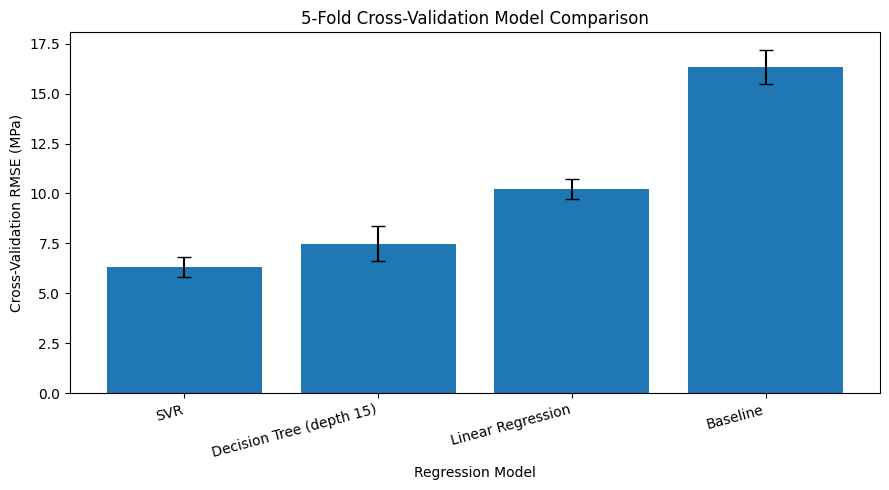

In [34]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    cv_results_df["Model"],
    cv_results_df["Mean RMSE"],
    yerr=cv_results_df["Std RMSE"],
    capsize=5
)

plt.ylabel("Cross-Validation RMSE (MPa)")
plt.xlabel("Regression Model")
plt.title("5-Fold Cross-Validation Model Comparison")

plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


Final Test Evaluation

In [35]:

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Retrain models using the complete development dataset
final_models = {
    "Baseline": clone(baseline_model),
    "Linear Regression": clone(linear_model),
    "Decision Tree": clone(tree_model),
    "SVR": clone(svr_model)
}

test_results = []

for name, model in final_models.items():

    # Train on the complete development dataset
    model.fit(X_dev, y_dev)

    # Predict the untouched test observations
    predictions = model.predict(X_test)

    # Calculate test metrics
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    test_results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2
    })

# Display the final comparison
test_results_df = pd.DataFrame(test_results)

test_results_df = test_results_df.sort_values(
    by="RMSE"
).reset_index(drop=True)

display(test_results_df.round(3))


,Model,MAE,RMSE,R²
0,SVR,4.032,5.605,0.875
1,Decision Tree,4.393,6.383,0.838
2,Linear Regression,8.938,11.147,0.505
3,Baseline,12.907,15.855,-0.001


**Prediction Error Analysis**

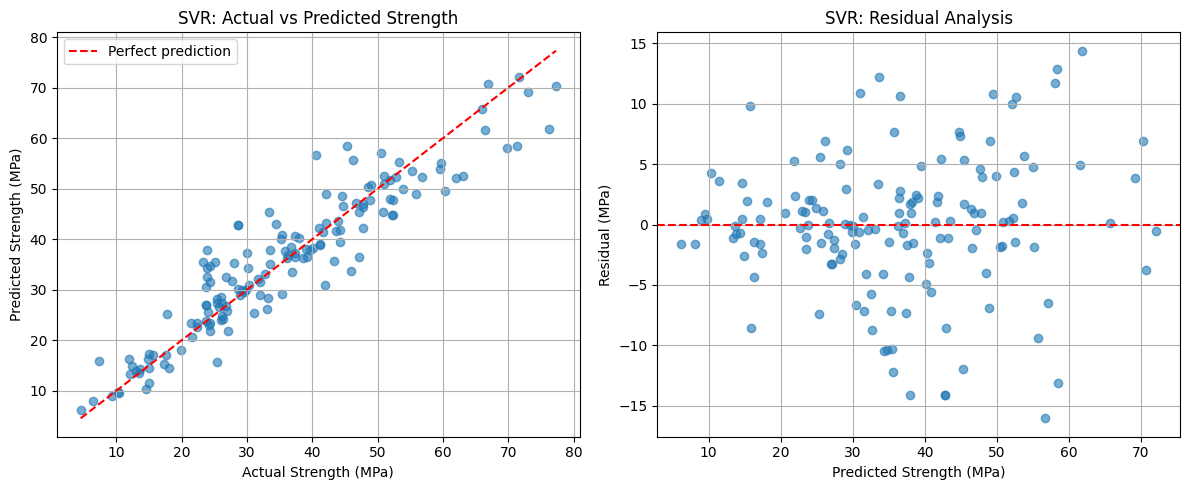

In [36]:

# Use the final SVR model
best_model = final_models["SVR"]

# Generate predictions on the test dataset
y_pred = best_model.predict(X_test)

# Calculate residuals
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Actual vs Predicted
axes[0].scatter(y_test, y_pred, alpha=0.6)

axes[0].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--",
    label="Perfect prediction"
)

axes[0].set_xlabel("Actual Strength (MPa)")
axes[0].set_ylabel("Predicted Strength (MPa)")
axes[0].set_title("SVR: Actual vs Predicted Strength")
axes[0].legend()
axes[0].grid(True)

# Plot 2: Residuals
axes[1].scatter(y_pred, residuals, alpha=0.6)

axes[1].axhline(
    y=0,
    color="red",
    linestyle="--"
)

axes[1].set_xlabel("Predicted Strength (MPa)")
axes[1].set_ylabel("Residual (MPa)")
axes[1].set_title("SVR: Residual Analysis")
axes[1].grid(True)

plt.tight_layout()
plt.show()


Computational Efficiency Analysis

In [37]:

import time
import numpy as np
import pandas as pd
from sklearn.base import clone

# Number of timing repetitions
n_repeats = 30

runtime_results = []

for name, model in final_models.items():

    training_times = []
    prediction_times = []

    for _ in range(n_repeats):

        # Create a fresh model for each training run
        timed_model = clone(model)

        # Measure training time
        start = time.perf_counter()
        timed_model.fit(X_dev, y_dev)
        training_time = time.perf_counter() - start

        # Measure prediction time
        start = time.perf_counter()
        timed_model.predict(X_test)
        prediction_time = time.perf_counter() - start

        training_times.append(training_time)
        prediction_times.append(prediction_time)

    runtime_results.append({
        "Model": name,
        "Training Time (ms)": np.mean(training_times) * 1000,
        "Prediction Time (ms)": np.mean(prediction_times) * 1000
    })

# Create comparison table
runtime_df = pd.DataFrame(runtime_results)

runtime_df = runtime_df.sort_values(
    by="Training Time (ms)"
).reset_index(drop=True)

display(runtime_df.round(3))


,Model,Training Time (ms),Prediction Time (ms)
0,Baseline,0.523,0.120
1,Linear Regression,2.101,1.238
2,Decision Tree,9.290,1.599
3,SVR,148.202,11.299


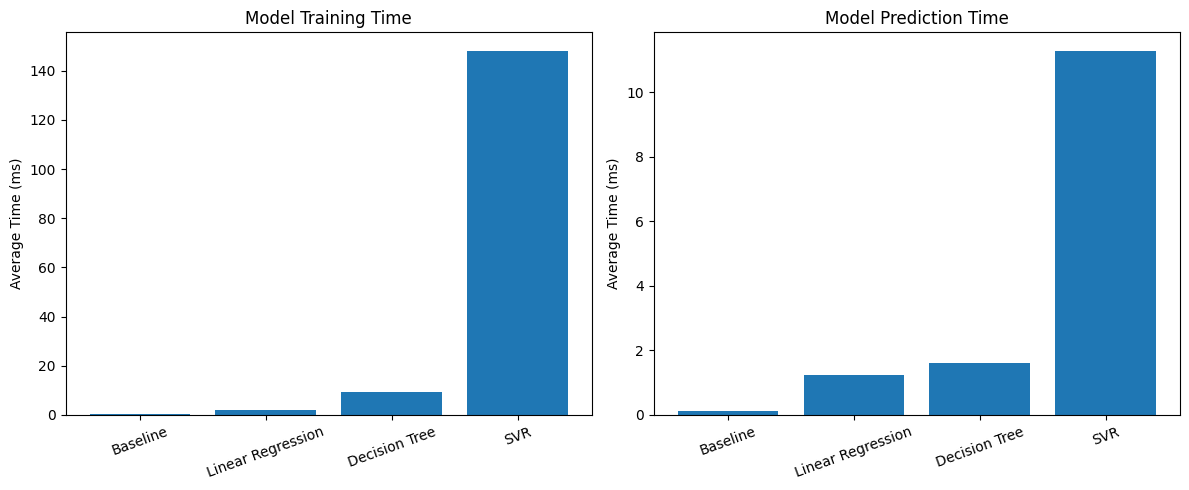

In [38]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Training time comparison
axes[0].bar(
    runtime_df["Model"],
    runtime_df["Training Time (ms)"]
)

axes[0].set_title("Model Training Time")
axes[0].set_ylabel("Average Time (ms)")
axes[0].tick_params(axis="x", rotation=20)

# Prediction time comparison
axes[1].bar(
    runtime_df["Model"],
    runtime_df["Prediction Time (ms)"]
)

axes[1].set_title("Model Prediction Time")
axes[1].set_ylabel("Average Time (ms)")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()
